# DATA3001项目进展总览

这份notebook用于解释Region A海洋漂流浮标轨迹预测项目目前已经完成的工作。它**不会重新生成或修改数据**，只读取 `build_processed_dataset.py` 已经产生的processed outputs，并检查所有关键数字是否可以复现。

阅读完以后，组员应该能够解释：我们已经完成了什么、5,117个预测样本如何产生、训练集/校准集/测试集如何划分，以及下一步如何回答RQ1。

## 1. 研究目标

对于每一个预测样本，使用过去**24小时**的纬度、经度、东西向速度和南北向速度，预测接下来**72小时**的位置。

$$X_i \in \mathbb{R}^{24\times4}\quad\longrightarrow\quad Y_i \in \mathbb{R}^{72\times2}$$

最终项目需要回答三个研究问题：

1. **RQ1——预测准确性：** 误差怎样随1至72小时的预测时长增长？学习模型是否优于速度持续性和空间平均流baseline？
2. **RQ2——不同动力环境：** 不同海洋动力regime中的可预测性是否不同？
3. **RQ3——预测不确定性：** Conformal prediction生成的预测区域能否达到可靠的coverage？不同regime中是否仍然可靠？

## 2. 已完成的数据处理流程

```text
Region A原始逐小时观测
        ↓
质量检查与review flags
        ↓
划分连续逐小时轨迹segments
        ↓
筛选至少包含96条观测的segments
        ↓
仅使用训练数据计算速度自相关和T_L
        ↓
将forecast origins间隔设为96小时
        ↓
生成5,117个预测样本
        ↓
以完整drifter为单位划分训练/校准/测试集
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from IPython import get_ipython

# 确保图表直接显示在notebook单元格下方。
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

# 从项目根目录或项目中的notebooks目录打开时，自动寻找processed数据。
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p for p in candidates if (p / 'data' / 'processed').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('请从data3001-project项目目录打开这份notebook。')

PROCESSED = PROJECT_ROOT / 'data' / 'processed'
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('项目根目录：', PROJECT_ROOT.resolve())
print('Processed数据目录：', PROCESSED.resolve())

项目根目录： /Users/roger/Documents/data3001-project
Processed数据目录： /Users/roger/Documents/data3001-project/data/processed


## 3. 读取已经生成的processed文件

五个processed文件分别承担不同作用：

- `region_A_observations.parquet`：清洗后的逐小时观测以及QC flags；
- `region_A_segments.parquet`：每一行代表一个连续轨迹segment；
- `drifter_splits.csv`：每一行代表一个drifter以及它所属的数据集；
- `forecast_origins.parquet`：每一行代表一个最终选中的预测样本；
- `qc_summary.csv`：可复现的关键统计结果汇总。

In [2]:
qc = pd.read_csv(PROCESSED / 'qc_summary.csv')
segments = pd.read_parquet(PROCESSED / 'region_A_segments.parquet')
splits = pd.read_csv(PROCESSED / 'drifter_splits.csv')
origins = pd.read_parquet(PROCESSED / 'forecast_origins.parquet')

print(f'QC汇总项目数： {len(qc):,}')
print(f'连续segments： {len(segments):,}')
print(f'Drifter数量：  {len(splits):,}')
print(f'预测样本数量： {len(origins):,}')

QC汇总项目数： 28
连续segments： 2,058
Drifter数量：  521
预测样本数量： 5,117


## 4. 数据与质量检查（QC）

QC flag不代表这条观测必须被删除。Flag的作用是保留潜在问题，方便之后人工检查和进行敏感性分析。例如，速度超过2 m/s的观测被标记但没有自动删除，因为数据中没有任何观测超过3 m/s。

In [3]:
qc_metrics = qc.set_index('metric')['value']
important_qc = [
    'raw_rows',
    'processed_observation_rows',
    'unique_drifters',
    'core_missing_after_processing',
    'speed_above_2_m_per_s',
    'speed_above_3_m_per_s',
    'land_mask_flagged_observations',
    'observations_missing_position_error',
    'observations_missing_velocity_error',
]
qc_name_cn = {
    'raw_rows': '原始观测行数',
    'processed_observation_rows': '处理后观测行数',
    'unique_drifters': '唯一drifter数量',
    'core_missing_after_processing': '处理后核心变量缺失数',
    'speed_above_2_m_per_s': '速度超过2 m/s的观测数',
    'speed_above_3_m_per_s': '速度超过3 m/s的观测数',
    'land_mask_flagged_observations': '被land mask标记的观测数',
    'observations_missing_position_error': '缺少位置误差信息的观测数',
    'observations_missing_velocity_error': '缺少速度误差信息的观测数',
}
qc_action_cn = {
    'Report': '仅报告',
    'Retain and review': '保留并检查',
    'Retain pending coastal review': '暂时保留，等待沿岸位置检查',
    'Retain with missingness flag': '保留并添加缺失标记',
}
qc_display = qc[qc['metric'].isin(important_qc)].copy()
qc_display['检查项目'] = qc_display['metric'].map(qc_name_cn)
qc_display['处理方式或解释'] = qc_display['action_or_interpretation'].map(qc_action_cn).fillna(qc_display['action_or_interpretation'])
display(qc_display[['检查项目', 'value', '处理方式或解释']].rename(columns={'value': '数值'}).reset_index(drop=True))

,检查项目,数值,处理方式或解释
0,原始观测行数,562944,仅报告
1,处理后观测行数,562944,仅报告
2,唯一drifter数量,521,仅报告
3,处理后核心变量缺失数,0,仅报告
4,速度超过2 m/s的观测数,245,保留并检查
5,速度超过3 m/s的观测数,0,保留并检查
6,被land mask标记的观测数,941,暂时保留，等待沿岸位置检查
7,缺少位置误差信息的观测数,1052,保留并添加缺失标记
8,缺少速度误差信息的观测数,24632,保留并添加缺失标记


## 5. 连续轨迹与96小时要求

每个预测case使用前24小时作为输入，再预测后72小时，因此至少需要 **96条连续的逐小时观测**。同一drifter的记录如果出现时间断点，就会被拆分为不同的连续轨迹段（continuous segments）。

,项目,结果
0,连续轨迹段总数,2058
1,满足至少96条观测的轨迹段,939
2,合格比例,45.6%


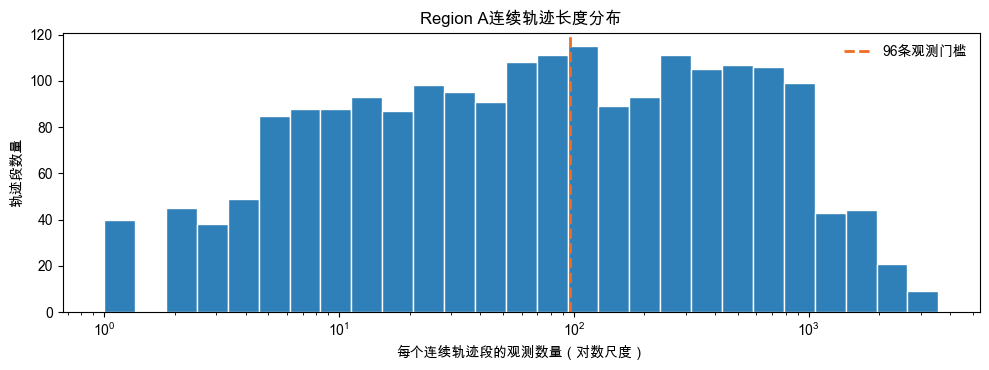

In [4]:
eligible = segments['eligible_24_to_72'].astype(bool)
segment_summary = pd.DataFrame({
    '项目': ['连续轨迹段总数', '满足至少96条观测的轨迹段', '合格比例'],
    '结果': [len(segments), int(eligible.sum()), f'{eligible.mean():.1%}'],
})
display(segment_summary)

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.logspace(0, np.log10(segments['n_observations'].max() + 1), 28)
ax.hist(segments['n_observations'], bins=bins, color='#2f7fb8', edgecolor='white')
ax.axvline(96, color='#f26b21', linestyle='--', linewidth=2, label='96条观测门槛')
ax.set_xscale('log')
ax.set_xlabel('每个连续轨迹段的观测数量（对数尺度）')
ax.set_ylabel('轨迹段数量')
ax.set_title('Region A连续轨迹长度分布')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. 为什么443,295个窗口最后变成5,117个case

如果把96小时窗口每次向前移动1小时，会产生443,295个潜在窗口；但是相邻窗口共享96条观测中的95条。若把它们当作互相独立的样本，会造成严重的伪重复（pseudoreplication），让有效样本量看起来远大于真实情况。

因此，我们只使用**训练集中符合要求的轨迹段**估计速度自相关。Lagrangian积分时间尺度用于概括速度信息通常能维持相关多长时间；它是判断时间依赖性的证据，并不是预测模型。最终把forecast origin的间隔设为96小时，也就是完整的24小时输入加72小时目标窗口长度，因此同一轨迹段中相邻的入选case不会直接共享观测。

In [5]:
dependence_metrics = [
    'potential_overlapping_windows',
    'lag_1_velocity_autocorrelation',
    'lag_at_or_below_one_over_e_hours',
    'lagrangian_integral_timescale_hours',
    'selected_forecast_origin_spacing_hours',
    'selected_forecast_origins',
]
dependence_name_cn = {
    'potential_overlapping_windows': '每小时滑动产生的潜在重叠窗口',
    'lag_1_velocity_autocorrelation': '1小时lag速度自相关',
    'lag_at_or_below_one_over_e_hours': '自相关首次降至1/e以下的lag（小时）',
    'lagrangian_integral_timescale_hours': 'Lagrangian积分时间尺度（小时）',
    'selected_forecast_origin_spacing_hours': '最终forecast origin间隔（小时）',
    'selected_forecast_origins': '最终forecast cases数量',
}
dependence_display = qc[qc['metric'].isin(dependence_metrics)].copy()
dependence_display['指标'] = dependence_display['metric'].map(dependence_name_cn)
display(dependence_display[['指标', 'value']].rename(columns={'value': '数值'}).reset_index(drop=True))

,指标,数值
0,每小时滑动产生的潜在重叠窗口,443295
1,1小时lag速度自相关,0.953983
2,自相关首次降至1/e以下的lag（小时）,32
3,Lagrangian积分时间尺度（小时）,29.562
4,最终forecast origin间隔（小时）,96
5,最终forecast cases数量,5117


## 7. 一个forecast case到底是什么

`forecast_origins.parquet`中的每一行代表一次预测实验：

```text
一个drifter + 一个连续轨迹段 + 一个预测起点
        ├── 前24小时 = 模型输入 X
        └── 后72小时 = 预测目标 Y
```

因此，这5,117行是5,117个forecast cases，并不是5,117个不同的drifter。一个较长的drifter轨迹可以贡献多个互不直接重叠的case。

In [6]:
# 这里只展示理解case所需的核心字段，完整字段仍保留在parquet文件中。
case_columns = [
    'forecast_case_id', 'ID', 'segment_id', 'partition', 'origin_time',
]
case_display = origins[case_columns].head(6).copy()
case_display['origin_time'] = pd.to_datetime(case_display['origin_time']).dt.strftime('%Y-%m-%d %H:%M')
case_display = case_display.rename(columns={
    'forecast_case_id': 'Case ID',
    'ID': 'Drifter ID',
    'segment_id': '轨迹段ID',
    'partition': '所属数据集',
    'origin_time': '预测起点时间',
})
display(case_display)

,Case ID,Drifter ID,轨迹段ID,所属数据集,预测起点时间
0,1,35554,1,training,2012-09-03 05:00
1,2,35554,1,training,2012-09-07 05:00
2,3,35554,1,training,2012-09-11 05:00
3,4,35554,1,training,2012-09-15 05:00
4,5,35554,1,training,2012-09-19 05:00
5,6,35554,2,training,2012-10-01 12:00


## 8. 避免数据泄漏：按完整drifter划分数据集

使用固定随机种子3001，把521个完整drifter ID划分为：

- 70%的drifter → 训练集（training）；
- 15%的drifter → 校准集（calibration）；
- 剩余drifter → 测试集（test）。

如果某个drifter被分到训练集，那么它的**所有观测、所有轨迹段、所有24小时输入和72小时目标都留在训练集**。24/72表示一个case内部的输入与预测目标，并不是把前24小时当训练集、后72小时当测试集。这样才能避免同一个drifter同时出现在训练和测试中。

In [7]:
partition_order = ['training', 'calibration', 'test']
split_summary = pd.DataFrame({
    'drifters': splits.groupby('partition').size(),
    'eligible_drifters': (
        splits.assign(eligible=splits['n_eligible_segments'].gt(0))
        .groupby('partition')['eligible'].sum()
    ),
    'observations': splits.groupby('partition')['n_observations'].sum(),
    'eligible_segments': splits.groupby('partition')['n_eligible_segments'].sum(),
    'forecast_cases': origins.groupby('partition').size(),
}).loc[partition_order]
split_summary['case_percentage'] = 100 * split_summary['forecast_cases'] / split_summary['forecast_cases'].sum()
split_summary_cn = split_summary.rename(
    index={'training': '训练集', 'calibration': '校准集', 'test': '测试集'},
    columns={
        'drifters': 'Drifter数量',
        'eligible_drifters': '可产生case的drifter数量',
        'observations': '观测数量',
        'eligible_segments': '合格轨迹段数量',
        'forecast_cases': 'Forecast cases数量',
        'case_percentage': 'Cases占比（%）',
    },
)
display(split_summary_cn.round({'Cases占比（%）': 1}))

,Drifter数量,可产生case的drifter数量,观测数量,合格轨迹段数量,Forecast cases数量,Cases占比（%）
partition,,,,,,
训练集,364,311,392533,642,3591,70.2
校准集,78,66,85217,144,769,15.0
测试集,79,71,85194,153,757,14.8


## 9. 可复现性与数据泄漏自动检查

下面的检查用于确认：每个drifter只属于一个数据集；每个forecast origin的数据集标签与其drifter一致；同一轨迹段内相邻forecast origins至少相隔96小时。全部显示`True`才表示数据结构通过检查。

In [8]:
partition_map = splits.set_index('ID')['partition']
origin_partition_expected = origins['ID'].map(partition_map)
origin_times = pd.to_datetime(origins['origin_time'], utc=True)
spacing = (
    origins.assign(origin_time_parsed=origin_times)
    .sort_values(['ID', 'segment_id', 'origin_time_parsed'])
    .groupby(['ID', 'segment_id'])['origin_time_parsed']
    .diff().dt.total_seconds().div(3600)
)

checks = pd.Series({
    '覆盖全部521个drifter': splits['ID'].nunique() == 521,
    '每个drifter只属于一个数据集': not splits['ID'].duplicated().any(),
    '每个forecast origin都有数据集标签': origin_partition_expected.notna().all(),
    'origin标签与drifter划分完全一致': origin_partition_expected.eq(origins['partition']).all(),
    '同一轨迹段内origin间隔至少96小时': spacing.dropna().ge(96).all(),
    'forecast cases总数等于5117': len(origins) == 5117,
}, name='是否通过')
display(checks.to_frame())
assert checks.all(), '至少一项数据完整性检查未通过。'

,是否通过
覆盖全部521个drifter,True
每个drifter只属于一个数据集,True
每个forecast origin都有数据集标签,True
origin标签与drifter划分完全一致,True
同一轨迹段内origin间隔至少96小时,True
forecast cases总数等于5117,True


## 10. 项目目前做到哪里

### 已完成

- 提取Region A数据并完成数据清单；
- 完成质量检查并保留需要复核的flags；
- 构造连续轨迹段；
- 检查轨迹段是否满足96条连续观测；
- 仅用训练数据计算vector velocity autocorrelation和$T_L$；
- 将forecast origin间隔设为96小时；
- 产生5,117个forecast origins；
- 按完整drifter完成无泄漏的数据划分；
- 完成proposal、README和poster所需的初步证据。

### 尚未完成

- 把每个case正式展开成可直接建模的24步输入和72步目标；
- 实现velocity-persistence baseline；
- 实现spatial mean-flow baseline；
- 训练一个统计或机器学习预测模型；
- 计算不同lead time的误差和forecast skill，回答RQ1；
- 定义物理regimes并比较不同regime下的表现，回答RQ2；
- 校准和评价conformal prediction regions，回答RQ3。

## 11. 下一份notebook：回答RQ1

RQ1建议在单独的notebook中完成，使上面的数据处理和审计结果保持稳定。下一份notebook需要：

1. 为5,117个origins构造`X`（24 × 4）和`Y`（72 × 2）；
2. 实现velocity persistence；
3. 仅用训练集实现spatial mean flow；
4. 只使用训练cases拟合一个预测模型；
5. 使用calibration set做模型选择或校准，不用于最终成绩汇报；
6. 冻结所有方法后，在757个test cases上进行最终评价；
7. 汇报1至72小时的separation-error曲线、median error、RMSE、integrated trajectory error，以及相对于baselines的skill。

Poster现在可以使用本notebook中已经完成的表格和轨迹段分布图；RQ1 notebook则会产生第一张真正的预测结果图。